<center><h1>Zhang_Zhengshu_HW4</h1></center>
<br>
<br>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

Problem 1 was the programming part of Homework 3. Its code is repeated here because Problem 2 uses the same features.

### (a) Obtain Data

Import packages

In [1]:
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%config InlineBackend.figure_format = "png"
pd.set_option("display.max_columns", 30)
pd.set_option("display.expand_frame_repr", False)

Get the AReM Data Set

The AReM data set has seven folders, one for each activity. Each file is one instance of a person performing the activity named by its folder. Each instance holds six time series named avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23 and var_rss23. There are 88 instances, and each time series has 480 values recorded every 250 milliseconds over 120 seconds.

In [2]:
DATA_DIR = "data/AReM"
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]


def dataset_number(file_name):
    """Return the number in a file name such as dataset12.csv."""
    return int(re.search("[0-9]+", file_name).group())


def csv_files(activity):
    """List the csv files of one activity folder in numeric order."""
    names = [name for name in os.listdir(f"{DATA_DIR}/{activity}") if name.endswith(".csv")]
    return sorted(names, key=dataset_number)


file_counts = pd.DataFrame({"activity": ACTIVITIES,
                            "files": [len(csv_files(activity)) for activity in ACTIVITIES]})
print(file_counts.to_string(index=False))
print("Total files:", file_counts["files"].sum())

activity  files
bending1      7
bending2      6
 cycling     15
   lying     15
 sitting     15
standing     15
 walking     15
Total files: 88


The six time series are numbered 1 to 6 in the order they appear in each file. Later parts of the homework refer to the time series by these numbers.

In [3]:
SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

series_numbers = pd.DataFrame({"time series": range(1, 7), "name": SERIES_NAMES})
print(series_numbers.to_string(index=False))

 time series      name
           1 avg_rss12
           2 var_rss12
           3 avg_rss13
           4 var_rss13
           5 avg_rss23
           6 var_rss23


Four files need minor cleaning, and the read_instance function below fixes all four while reading them, so the files on disk stay unchanged. Treating commas and spaces alike fixes the space separators in bending2/dataset4.csv, and ignoring the empty value after the extra final comma fixes cycling/dataset9.csv and cycling/dataset14.csv. The file sitting/dataset8.csv has no row for time 13500, so its features are computed from the 479 rows that are present. The printed report also lists standing/dataset5.csv, whose one stray tab needs no cleaning.

In [4]:
EXPECTED_ROWS = 480
STEP_MS = 250


def data_lines(text):
    """Return (line number, line) for every line that is not blank and not a # header."""
    lines = []
    for number, line in enumerate(text.splitlines(), start=1):
        stripped = line.strip()
        if stripped and not stripped.startswith("#"):
            lines.append((number, line))
    return lines


def read_instance(path):
    """Read one file into a table of the six time series, indexed by time."""
    with open(path) as source:
        text = source.read()
    times, rows = [], []
    for number, line in data_lines(text):
        tokens = line.replace(",", " ").split()
        if len(tokens) != 7:
            raise ValueError(f"{path}, line {number}: expected 7 values, found {len(tokens)}")
        try:
            values = [float(token) for token in tokens]
        except ValueError:
            raise ValueError(f"{path}, line {number}: found a value that is not a number")
        times.append(int(values[0]))
        rows.append(values[1:])
    return pd.DataFrame(rows, columns=SERIES_NAMES, index=pd.Index(times, name="time"))


def row_count_problem(instance):
    """Describe a wrong row count, or return None when the instance has 480 rows."""
    if len(instance) == EXPECTED_ROWS:
        return None
    expected_times = set(range(0, EXPECTED_ROWS * STEP_MS, STEP_MS))
    missing = sorted(expected_times - set(instance.index))
    note = f"{len(instance)} rows instead of {EXPECTED_ROWS}"
    if missing:
        note += ", missing time " + " ".join(str(t) for t in missing)
    return note


def format_problems(path):
    """Describe separator and trailing-character problems found in the raw text.

    Also return whether a plain comma split fails, meaning some row does not give 7 fields.
    """
    with open(path) as source:
        lines = [line for _, line in data_lines(source.read())]
    problems = []
    no_comma = sum("," not in line for line in lines)
    trailing_space = sum(line != line.rstrip() for line in lines)
    trailing_comma = sum(line.rstrip().endswith(",") for line in lines)
    if no_comma:
        problems.append(f"{no_comma} of {len(lines)} rows use spaces instead of commas")
    if trailing_space:
        problems.append(f"{trailing_space} of {len(lines)} rows end with a space or tab")
    if trailing_comma:
        problems.append(f"{trailing_comma} of {len(lines)} rows end with an extra comma")
    comma_split_fails = any(len(line.split(",")) != 7 for line in lines)
    return problems, comma_split_fails

In [5]:
instances = []
cleaning_notes = []
whitespace_notes = []
for activity in ACTIVITIES:
    for file_name in csv_files(activity):
        path = f"{DATA_DIR}/{activity}/{file_name}"
        data = read_instance(path)
        problems, comma_split_fails = format_problems(path)
        row_note = row_count_problem(data)
        if row_note:
            problems.append(row_note)
        if comma_split_fails or row_note:
            cleaning_notes.append(f"{path}: " + ", ".join(problems))
        elif problems:
            whitespace_notes.append(f"{path}: " + ", ".join(problems))
        instances.append({"activity": activity, "file": file_name, "path": path, "data": data})

print("Instances loaded:", len(instances))
print("Files that needed cleaning:")
for note in cleaning_notes:
    print("  " + note)
print("Files with stray whitespace only, which needs no cleaning:")
for note in whitespace_notes:
    print("  " + note)

Instances loaded: 88
Files that needed cleaning:
  data/AReM/bending2/dataset4.csv: 480 of 480 rows use spaces instead of commas, 480 of 480 rows end with a space or tab
  data/AReM/cycling/dataset9.csv: 1 of 480 rows end with an extra comma
  data/AReM/cycling/dataset14.csv: 1 of 480 rows end with an extra comma
  data/AReM/sitting/dataset8.csv: 479 rows instead of 480, missing time 13500
Files with stray whitespace only, which needs no cleaning:
  data/AReM/standing/dataset5.csv: 1 of 480 rows end with a space or tab


### (b) Splitting Data

The test data are instances dataset1 and dataset2 of bending1 and bending2, plus instances dataset1, dataset2 and dataset3 of the other five activities. All other instances are the train data. The split gives 19 test instances and 69 train instances.

In [6]:
def split_of(activity, file_name):
    """Return "test" or "train" for one dataset file, following the rule in 1(b)."""
    test_count = 2 if activity in ("bending1", "bending2") else 3
    return "test" if dataset_number(file_name) <= test_count else "train"

In [7]:
for item in instances:
    item["split"] = split_of(item["activity"], item["file"])

splits = [item["split"] for item in instances]
print("Train instances:", splits.count("train"))
print("Test instances:", splits.count("test"))
print()

split_table = pd.DataFrame({
    "activity": ACTIVITIES,
    "train": [sum(i["activity"] == a and i["split"] == "train" for i in instances) for a in ACTIVITIES],
    "test": [sum(i["activity"] == a and i["split"] == "test" for i in instances) for a in ACTIVITIES],
})
print(split_table.to_string(index=False))

Train instances: 69
Test instances: 19

activity  train  test
bending1      5     2
bending2      4     2
 cycling     12     3
   lying     12     3
 sitting     12     3
standing     12     3
 walking     12     3


### (c) Feature Extraction

#### i. Research

Time-domain features are summary numbers computed directly from the values of a time series. The table lists the time-domain features most often used for time series classification. Reference 12 gives a similar list for activity recognition.

| Feature | What it measures |
|---|---|
| Minimum | The smallest value in the time series |
| Maximum | The largest value in the time series |
| Range | The gap between the largest and smallest values |
| Mean | The average value |
| Median | The middle value after sorting the values |
| Standard deviation | How far the values typically spread around the mean |
| Variance | The square of the standard deviation |
| First quartile | The value below which a quarter of the values fall |
| Third quartile | The value below which three quarters of the values fall |
| Interquartile range | The spread of the middle half of the values |
| Root mean square | The typical size of the values, with large values counting more |
| Mean absolute deviation | The average distance of the values from the mean |
| Skewness | Whether the values lean more to one side of the mean |
| Kurtosis | How often values far from the mean appear |
| Zero-crossing rate | How often the time series changes sign |
| Mean-crossing rate | How often the time series crosses its own mean |
| Number of peaks | How many local high points the time series has |
| Signal energy | The sum of the squared values |
| Autocorrelation at lag one | How closely each value follows the value before it |
| Slope of a fitted straight line | Whether the time series trends up or down over time |
| Mean absolute change | The average size of the step from one value to the next |

Part 1(c)ii asks for seven features from the table, namely the minimum, maximum, mean, median, standard deviation, first quartile and third quartile. The seven features are computed for each of the six time series in every instance.

#### ii. Extraction

The feature table has one row for each of the 88 instances and one column for each of the 42 features. Each feature is one of the seven statistics of 1(c)ii computed on one of the six time series, and the seven statistics are called feature types from here on. Each column name joins a feature type and a time series number. For example, std_2 is the standard deviation of time series 2, and q1_6 is the first quartile of time series 6. The table also keeps four bookkeeping columns named instance, activity, source_file and split, which are not features.

In [8]:
FEATURES = ["min", "max", "mean", "median", "std", "q1", "q3"]
FEATURE_COLUMNS = [f"{feature}_{number}" for number in range(1, 7) for feature in FEATURES]
DDOF = 1  # sample standard deviation, used everywhere in this notebook


def series_features(values, ddof=DDOF):
    """Return the seven features of one time series in the order of FEATURES."""
    values = np.asarray(values, dtype=float)
    return [np.min(values), np.max(values), np.mean(values), np.median(values),
            np.std(values, ddof=ddof), np.percentile(values, 25), np.percentile(values, 75)]

In [9]:
rows = []
for number, item in enumerate(instances, start=1):
    row = {"instance": number, "activity": item["activity"],
           "source_file": item["path"], "split": item["split"]}
    for series_number, name in enumerate(SERIES_NAMES, start=1):
        for feature, value in zip(FEATURES, series_features(item["data"][name])):
            row[f"{feature}_{series_number}"] = value
    rows.append(row)

features = pd.DataFrame(rows, columns=["instance", "activity", "source_file", "split"] + FEATURE_COLUMNS)
print("Shape of the feature columns:", features[FEATURE_COLUMNS].shape)

Shape of the feature columns: (88, 42)


The feature table is too wide to print at once, so it is shown in six parts, one for each time series. The values shown are rounded to two decimals, while the table itself keeps full precision.

In [10]:
for number in range(1, 4):
    columns = [f"{feature}_{number}" for feature in FEATURES]
    display(features[["instance", "activity", "split"] + columns].head().round(2))

,instance,activity,split,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1
0,1,bending1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00
1,2,bending1,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67
2,3,bending1,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00
3,4,bending1,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00
4,5,bending1,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75


,instance,activity,split,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2
0,1,bending1,test,0.0,1.30,0.36,0.43,0.32,0.00,0.50
1,2,bending1,test,0.0,1.22,0.37,0.47,0.29,0.00,0.50
2,3,bending1,train,0.0,1.70,0.43,0.47,0.34,0.00,0.50
3,4,bending1,train,0.0,3.00,0.70,0.50,0.63,0.00,1.12
4,5,bending1,train,0.0,2.83,0.54,0.50,0.41,0.43,0.71


,instance,activity,split,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3
0,1,bending1,test,4.0,29.50,19.04,19.25,4.46,16.00,23.25
1,2,bending1,test,2.0,29.50,20.10,21.00,3.89,19.00,22.25
2,3,bending1,train,6.5,29.75,22.12,23.00,3.03,19.75,24.00
3,4,bending1,train,8.5,30.00,22.18,23.00,3.81,20.50,24.37
4,5,bending1,train,3.0,28.25,19.01,19.12,4.09,16.50,22.06


In [11]:
for number in range(4, 7):
    columns = [f"{feature}_{number}" for feature in FEATURES]
    display(features[["instance", "activity", "split"] + columns].head().round(2))

,instance,activity,split,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4
0,1,bending1,test,0.0,7.23,0.83,0.50,0.97,0.00,1.12
1,2,bending1,test,0.0,5.76,0.88,0.50,1.05,0.00,1.14
2,3,bending1,train,0.0,4.44,0.50,0.43,0.55,0.00,0.83
3,4,bending1,train,0.0,5.15,0.99,0.83,0.95,0.43,1.30
4,5,bending1,train,0.0,6.42,0.84,0.50,0.93,0.43,1.12


,instance,activity,split,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5
0,1,bending1,test,27.25,38.25,34.31,35.0,2.19,33.00,36.00
1,2,bending1,test,27.67,38.50,33.02,33.0,2.00,32.00,34.50
2,3,bending1,train,29.00,38.50,35.59,36.0,2.00,35.36,36.50
3,4,bending1,train,20.00,38.67,33.49,35.0,3.85,30.46,36.33
4,5,bending1,train,23.67,37.50,29.86,30.0,2.41,28.46,31.25


,instance,activity,split,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,1,bending1,test,0.0,1.92,0.57,0.43,0.58,0.0,1.30
1,2,bending1,test,0.0,3.11,0.57,0.43,0.60,0.0,1.30
2,3,bending1,train,0.0,1.79,0.49,0.43,0.51,0.0,0.94
3,4,bending1,train,0.0,2.18,0.61,0.50,0.52,0.0,1.00
4,5,bending1,train,0.0,1.79,0.38,0.43,0.39,0.0,0.50


#### iii. Standard Deviation

The table below gives the standard deviation of each of the 42 features, together with a 90% bootstrap confidence interval. All 88 instances are used, because 1(c)iii asks about every feature extracted from the data. The bootstrap resamples the 88 instances with replacement 10000 times, recomputes each standard deviation every time, and keeps the middle 90% of the results as the interval. The random seed is fixed so that the numbers can be reproduced. A narrow interval means the standard deviation of a feature barely changes between resamples, while a wide interval means a few unusual instances can shift that standard deviation a lot.

In [12]:
N_BOOT = 10000
CI_PERCENTILES = (5, 95)  # the middle 90% of the bootstrap values


def bootstrap_std_ci(X, n_boot=N_BOOT, seed=0, percentiles=CI_PERCENTILES):
    """Bootstrap interval for the standard deviation of each column of X.

    Each replicate resamples the rows (instances) with replacement and uses the
    same rows for every column.
    """
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    boot_stds = np.empty((n_boot, X.shape[1]))
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot_stds[b] = X[idx].std(axis=0, ddof=DDOF)
    lower = np.percentile(boot_stds, percentiles[0], axis=0)
    upper = np.percentile(boot_stds, percentiles[1], axis=0)
    return lower, upper

In [13]:
X = features[FEATURE_COLUMNS].to_numpy()
ci_lower, ci_upper = bootstrap_std_ci(X)

std_table = pd.DataFrame({"feature": FEATURE_COLUMNS,
                          "std": X.std(axis=0, ddof=DDOF),
                          "ci_lower": ci_lower,
                          "ci_upper": ci_upper})
print(std_table.round(4).to_string(index=False))

 feature    std  ci_lower  ci_upper
   min_1 9.5700    8.2569   10.7849
   max_1 4.3944    3.3435    5.2918
  mean_1 5.3357    4.7213    5.8777
median_1 5.4401    4.8068    6.0035
   std_1 1.7722    1.5716    1.9466
    q1_1 6.1536    5.5824    6.6483
    q3_1 5.1389    4.3421    5.8473
   min_2 0.0000    0.0000    0.0000
   max_2 5.0627    4.6258    5.4086
  mean_2 1.5742    1.3957    1.7053
median_2 1.4122    1.2367    1.5437
   std_2 0.8841    0.8034    0.9418
    q1_2 0.9464    0.8300    1.0350
    q3_2 2.1253    1.8932    2.2952
   min_3 2.9565    2.7564    3.1095
   max_3 4.8751    4.1941    5.4636
  mean_3 4.0084    3.4283    4.4992
median_3 4.0364    3.4424    4.5449
   std_3 0.9467    0.7647    1.1254
    q1_3 4.2207    3.6395    4.7070
    q3_3 4.1716    3.5567    4.7001
   min_4 0.0000    0.0000    0.0000
   max_4 2.1836    1.9759    2.3627
  mean_4 1.1661    1.0742    1.2225
median_4 1.1456    1.0536    1.2011
   std_4 0.4582    0.4208    0.4865
    q1_4 0.8436    0.7739   

#### iv. Select Features

The three most important feature types are chosen using the 69 train instances only, because choosing features is part of building a model and the test instances are kept aside. The choice is between the seven feature types min, max, mean, median, std, q1 and q3. Two pieces of evidence are used, namely how well each feature type separates the activities and how much two feature types carry the same information.

The first piece of evidence is separation. For each feature, the mean and the standard deviation of its values are computed over the train instances of each activity. The separation of the feature is the standard deviation of the seven means divided by the average of the seven standard deviations. A large separation means the activities sit far apart compared with how much the instances of one activity vary. The separation of a feature type is the average separation of its six features. The features min_2 and min_4 equal 0 for every train instance, so they cannot separate the activities and their separation is set to 0.

In [14]:
def separation(values, groups):
    """Spread of the activity means divided by the average spread within an activity."""
    if values.nunique() == 1:
        return 0.0  # a feature that never changes cannot separate the activities
    by_activity = values.groupby(groups)
    return by_activity.mean().std(ddof=DDOF) / by_activity.std(ddof=DDOF).mean()

In [15]:
train = features[features["split"] == "train"]

column_separation = pd.Series({column: separation(train[column], train["activity"])
                               for column in FEATURE_COLUMNS})
type_separation = pd.Series({feature: column_separation[[f"{feature}_{s}" for s in range(1, 7)]].mean()
                             for feature in FEATURES}, name="separation")
print(type_separation.round(3).to_frame().to_string())

        separation
min          0.969
max          1.651
mean         5.420
median       5.405
std          2.662
q1           3.916
q3           5.310


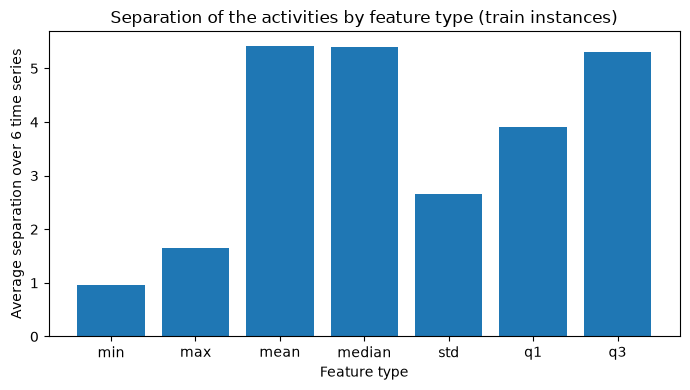

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(FEATURES, type_separation.values)
ax.set_title("Separation of the activities by feature type (train instances)")
ax.set_xlabel("Feature type")
ax.set_ylabel("Average separation over 6 time series")
fig.tight_layout()
plt.show()

The second piece of evidence is correlation. Two feature types with a high correlation carry nearly the same information, so choosing both adds little beyond choosing one. For each pair of feature types, the table gives the absolute correlation between their features on the same time series, averaged over the six time series. Correlation is not defined for min_2 and min_4 because they never change, so the min row and the min column average over the other four time series.

In [17]:
abs_corr = train[FEATURE_COLUMNS].corr().abs()

type_correlation = pd.DataFrame(index=FEATURES, columns=FEATURES, dtype=float)
for f in FEATURES:
    for g in FEATURES:
        pairs = [abs_corr.loc[f"{f}_{s}", f"{g}_{s}"] for s in range(1, 7)]
        type_correlation.loc[f, g] = np.nanmean(pairs)
print(type_correlation.round(2).to_string())

         min   max  mean  median   std    q1    q3
min     1.00  0.36  0.59    0.57  0.40  0.60  0.52
max     0.36  1.00  0.79    0.75  0.63  0.71  0.82
mean    0.59  0.79  1.00    0.99  0.60  0.98  0.98
median  0.57  0.75  0.99    1.00  0.61  0.98  0.96
std     0.40  0.63  0.60    0.61  1.00  0.66  0.57
q1      0.60  0.71  0.98    0.98  0.66  1.00  0.93
q3      0.52  0.82  0.98    0.96  0.57  0.93  1.00


The three chosen feature types are mean, std and max. Mean separates the activities best (5.42). Median, q1 and q3 are left out because their average correlation with mean is 0.98 or 0.99, so they carry nearly the same information as mean. Among the remaining feature types, std separates the activities best (2.66) and has a correlation of only 0.60 with mean. Max is preferred to min because min separates the activities worst (0.97), and a feature type that separates poorly does little to tell the activities apart. Max also overlaps less with mean and std, with average correlations of 0.79 and 0.63.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Problem 2(a) has two classes. The class bending holds the instances of bending1 and bending2, and the class other holds the instances of the remaining five activities. The table counts the instances of each class in the train and test data.

In [18]:
BENDING = ["bending1", "bending2"]
CLASSES = ["bending", "other"]
CLASS_COLORS = {"bending": "tab:red", "other": "tab:blue"}


def binary_class(activity):
    """Return "bending" for bending1 and bending2, and "other" for every other activity."""
    return "bending" if activity in BENDING else "other"


class_counts = pd.crosstab(features["split"], features["activity"].map(binary_class).rename("class"))
print(class_counts.loc[["train", "test"], CLASSES].to_string())

class  bending  other
split                
train        9     60
test         4     15


The scatter plots show mean, std and max, the three feature types chosen in 1(c)iv, on time series 1, 2 and 6 (avg_rss12, var_rss12 and var_rss23), which gives nine features. Only the 69 train instances are plotted, and the color of each point shows its class. Each pair of features is plotted once below the diagonal, and each diagonal panel shows how one feature is spread within each class. The plots are drawn with seaborn.pairplot (Reference 14).

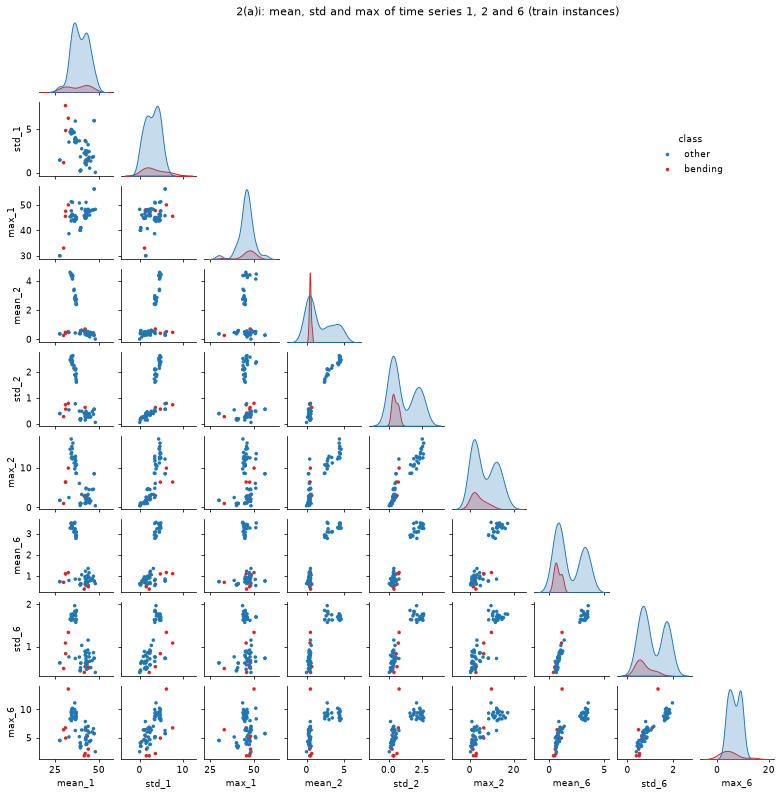

In [19]:
CHOSEN_TYPES = ["mean", "std", "max"]
PLOT_SERIES = [1, 2, 6]
PLOT_ORDER = ["other", "bending"]  # bending is drawn last so its few points stay on top
PLOT_DPI = 68  # keeps the scatter plot matrices small enough for the notebook


def pair_plot(table, columns, title):
    """Scatter plot matrix of the given feature columns, colored by class."""
    data = table[columns].assign(**{"class": table["activity"].map(binary_class)})
    with plt.rc_context({"figure.dpi": PLOT_DPI}):
        grid = sns.pairplot(data, hue="class", hue_order=PLOT_ORDER, palette=CLASS_COLORS,
                            corner=True, height=1.3, plot_kws={"s": 14, "linewidth": 0})
        sns.move_legend(grid, "upper right", bbox_to_anchor=(0.85, 0.85))
        grid.figure.suptitle(title, y=1.0)
        plt.show()


plot_columns = [f"{feature}_{number}" for number in PLOT_SERIES for feature in CHOSEN_TYPES]
pair_plot(train, plot_columns, "2(a)i: mean, std and max of time series 1, 2 and 6 (train instances)")

The scatter plots show that no single feature separates bending from the other activities, because the red bending points overlap with blue points in every panel. The features of time series 6 separate the two classes best. The bending points have small values of mean_6 and std_6, far from a separate group of other points with large values. Many other points also have small values of mean_6 and std_6, so these features alone cannot tell bending apart from those points.

#### ii. Splitted Plots

Part 2(a)ii cuts each time series into two segments, and later parts use l segments for l from 1 to 20, so the function segment_features takes l as an argument. It cuts each of the six time series of an instance into l segments of nearly equal length with numpy.array_split (Reference 13) and computes the seven feature types of Problem 1 on every segment. When the length is not a multiple of l, the first segments get one extra value, so the 479 values of sitting/dataset8.csv give segments of 240 and 239 values for l = 2. Each column name joins the feature type, the time series number and the segment number, so mean_6_seg2 is the mean of the second segment of time series 6. For l = 1 the columns hold the same values as the Problem 1 table, with _seg1 added to each name. The argument split keeps only the train or only the test instances, so that 2(a)v can cut the test instances in the same way.

In [20]:
def segment_features(l, split=None):
    """Feature table with each time series cut into l segments of nearly equal length.

    The columns are named type_series_segK. With split="train" or split="test" only those
    instances are kept, otherwise all 88 instances are used.
    """
    rows = []
    for number, item in enumerate(instances, start=1):
        if split is not None and item["split"] != split:
            continue
        row = {"instance": number, "activity": item["activity"],
               "source_file": item["path"], "split": item["split"]}
        for series_number, name in enumerate(SERIES_NAMES, start=1):
            segments = np.array_split(item["data"][name].to_numpy(), l)
            for segment_number, segment in enumerate(segments, start=1):
                for feature, value in zip(FEATURES, series_features(segment)):
                    row[f"{feature}_{series_number}_seg{segment_number}"] = value
        rows.append(row)
    return pd.DataFrame(rows)


def segment_columns(l):
    """Names of the 42 * l feature columns of segment_features(l), in table order."""
    return [f"{feature}_{number}_seg{segment}" for number in range(1, 7)
            for segment in range(1, l + 1) for feature in FEATURES]

In [21]:
train_l2 = segment_features(2, split="train")
print("Shape of the feature columns for l = 2 (train instances):", train_l2[segment_columns(2)].shape)

Shape of the feature columns for l = 2 (train instances): (69, 84)


For l = 2 each segment is one half of a time series, and mean, std and max of both halves of time series 1, 2 and 6 give 18 features. A single scatter plot of all 18 features would be too large to read, so the first halves and the second halves are shown in two separate plots with the same colors as 2(a)i.

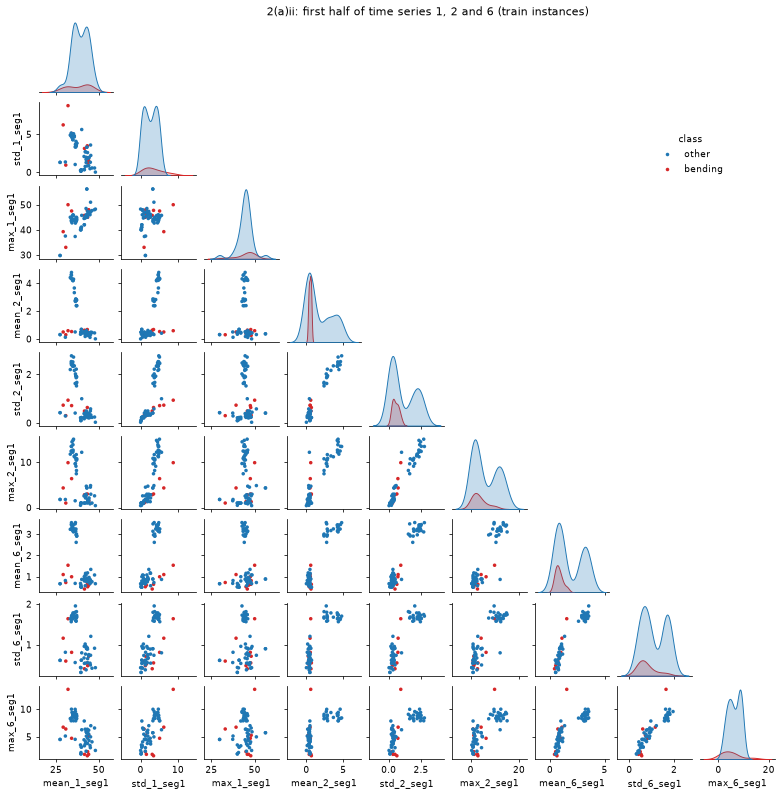

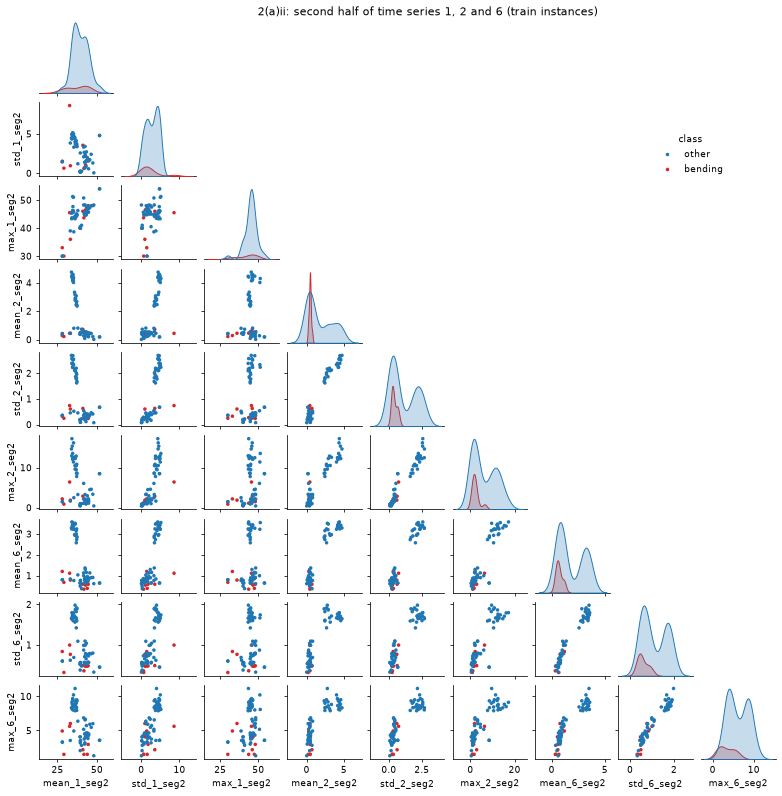

In [22]:
for segment in (1, 2):
    columns = [f"{feature}_{number}_seg{segment}" for number in PLOT_SERIES for feature in CHOSEN_TYPES]
    half = "first" if segment == 1 else "second"
    pair_plot(train_l2, columns, f"2(a)ii: {half} half of time series 1, 2 and 6 (train instances)")

There is no considerable difference between the plots of 2(a)ii and the plot of 2(a)i. In both halves, as in 2(a)i, the bending points have small values of mean_6 and std_6 and overlap with many other points in every panel. The only changes are shifts of single points. In the first half one bending point reaches the group of other points with large values on std_6_seg1, and in the second half the largest bending values of max_2_seg2 and max_6_seg2 are lower than in the first half. Splitting each time series in two doubles the number of features but does not make the two classes look much more separated.

#### iii. Time Series Segments

2(a)iii cuts each time series of the train instances into l segments with segment_features, for every l from 1 to 20. The features are mean, std and max on every segment of all six time series, because these are the three feature types selected in 1(c)iv. So there are 18 * l features for each l. Recursive feature elimination (RFE, Reference 17) then keeps p of the 18 * l features. RFE fits a logistic regression, drops the feature with the smallest coefficient and repeats, so the features are first standardized (Reference 19) to put the coefficients on one scale. The logistic regression has no penalty, which scikit-learn gives when the budget C of footnote 3 is set to infinity (Reference 16). Every fit stops after at most 100 iterations, because footnote 5 suggests stopping early when the classes can be separated. Cross-validation then picks the best pair (l, p), as described below.

In [23]:
# Footnote 5 expects unpenalized fits on separable classes to stop early, so this warning is expected.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

MAX_ITER = 100
L_VALUES = range(1, 21)
FIG_DPI = 80  # small figures keep the notebook size down


def logistic():
    """Logistic regression without a penalty (C is infinite) and a fixed iteration limit."""
    return LogisticRegression(C=np.inf, max_iter=MAX_ITER)


def model_columns(l):
    """The 18 * l columns of mean, std and max on every segment of the six time series."""
    return [column for column in segment_columns(l) if column.split("_")[0] in CHOSEN_TYPES]


def is_bending(table):
    """1 for a bending instance and 0 for an other instance."""
    return (table["activity"].map(binary_class) == "bending").astype(int).to_numpy()


train_tables = {l: segment_features(l, split="train") for l in L_VALUES}
y_train = is_bending(train_tables[1])
print("Train instances:", len(y_train), " bending:", y_train.sum(), " other:", len(y_train) - y_train.sum())
print("Features for l = 1 and l = 20:", len(model_columns(1)), "and", len(model_columns(20)))

Train instances: 69  bending: 9  other: 60
Features for l = 1 and l = 20: 18 and 360


The cross-validation is stratified 5-fold cross-validation (CV, Reference 18), because only 9 of the 69 train instances are bending and a plain 5-fold split could leave a fold with no bending instance. Stratifying keeps the share of bending instances about the same in every fold. In each of the five rounds, one fold is held out for scoring, and the model is fit on the other four folds, called the training part. The same folds are used for every l and every p, so all pairs (l, p) are compared on the same split. The table counts the instances in each held-out fold.

In [24]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
             .split(np.zeros(len(y_train)), y_train))
fold_table = pd.DataFrame({"fold": range(1, 6),
                           "held-out instances": [len(held) for _, held in folds],
                           "held-out bending": [int(y_train[held].sum()) for _, held in folds]})
print(fold_table.to_string(index=False))

 fold  held-out instances  held-out bending
    1                  14                 2
    2                  14                 2
    3                  14                 2
    4                  14                 2
    5                  13                 1


The right way to cross-validate is to repeat the whole model building in every round. The scaler and RFE are fit on the training part only, and the accuracy is measured on the held-out fold. The wrong way is to run feature selection once on all 69 train instances and only then cross-validate the logistic regression on the chosen features. In the wrong way the held-out instances have already helped to pick the features, so the CV accuracy comes out too optimistic. The code below uses the right way.

Because RFE removes one feature at a time, the p features it keeps are the p best-ranked features of a single run that goes all the way down to one feature. So the code runs RFE once for each l and each round, and for each p refits the logistic regression on the p best-ranked features. The CV accuracy of a pair (l, p) is the mean accuracy over the 5 held-out folds. The pair with the highest CV accuracy is chosen, and ties go to the smallest l and then the smallest p, which is the simplest model.

In [25]:
def fold_accuracies(X, y, folds):
    """Right-way CV accuracy for every p, with one row per p and one column per fold.

    The scaler and RFE only ever see the training part of a fold.
    """
    n_features = X.shape[1]
    accuracy = np.empty((n_features, len(folds)))
    for k, (fit_rows, held_rows) in enumerate(folds):
        scaler = StandardScaler().fit(X[fit_rows])
        X_fit, X_held = scaler.transform(X[fit_rows]), scaler.transform(X[held_rows])
        ranking = RFE(logistic(), n_features_to_select=1, step=1).fit(X_fit, y[fit_rows]).ranking_
        for p in range(1, n_features + 1):
            keep = ranking <= p
            model = logistic().fit(X_fit[:, keep], y[fit_rows])
            accuracy[p - 1, k] = accuracy_score(y[held_rows], model.predict(X_held[:, keep]))
    return accuracy


def best_row(grid):
    """Row with the highest CV accuracy, ties broken by the smallest l and then the smallest p."""
    score = grid["cv_accuracy"].round(10)  # rounding removes floating-point noise before comparing
    return grid[score == score.max()].sort_values(["l", "p"]).iloc[0]


rows = []
for l in L_VALUES:
    accuracy = fold_accuracies(train_tables[l][model_columns(l)].to_numpy(), y_train, folds)
    for p in range(1, accuracy.shape[0] + 1):
        rows.append({"l": l, "p": p, "cv_accuracy": accuracy[p - 1].mean(),
                     **{f"fold_{k + 1}": accuracy[p - 1, k] for k in range(len(folds))}})
cv_grid = pd.DataFrame(rows)

best_per_l = pd.DataFrame([best_row(cv_grid[cv_grid["l"] == l]) for l in L_VALUES])
best_per_l = best_per_l.astype({"l": int, "p": int})
print(best_per_l[["l", "p", "cv_accuracy"]].round(4).to_string(index=False))

 l  p  cv_accuracy
 1  4       0.9714
 2  8       0.9714
 3  3       0.9560
 4 37       0.9418
 5  1       0.9418
 6 11       0.9560
 7  2       0.9418
 8 12       0.9275
 9  6       0.9560
10 15       0.9703
11  1       0.9560
12  1       0.9560
13  2       0.9714
14  1       0.9418
15 34       0.9418
16  4       0.9560
17  6       0.9703
18  1       0.9560
19  3       0.9703
20  1       0.9560


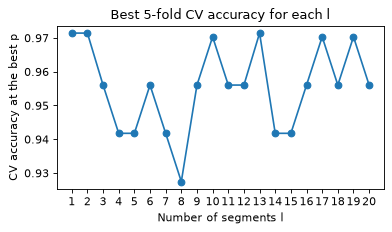

In [26]:
with plt.rc_context({"figure.dpi": FIG_DPI}):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(best_per_l["l"], best_per_l["cv_accuracy"], marker="o")
    ax.set_title("Best 5-fold CV accuracy for each l")
    ax.set_xlabel("Number of segments l")
    ax.set_ylabel("CV accuracy at the best p")
    ax.set_xticks(list(L_VALUES))
    fig.tight_layout()
    plt.show()

In [27]:
best = best_row(cv_grid)
best_l, best_p = int(best["l"]), int(best["p"])
print(f"Chosen pair: l = {best_l}, p = {best_p}, CV accuracy = {best['cv_accuracy']:.4f}")

Chosen pair: l = 1, p = 4, CV accuracy = 0.9714


The highest CV accuracy is 0.9714, reached by the three pairs (l, p) = (1, 4), (2, 8) and (13, 2). The tie rule picks l = 1 and p = 4, so the whole time series is used without any split. For the other values of l the best CV accuracy stays between 0.9275 and 0.9714, so cutting the time series into more segments does not improve the model here.

#### iv. Confusion Matrix

The final model uses l = 1 and p = 4. The scaler, RFE and the logistic regression are fit again on all 69 train instances, and the four features that RFE keeps are printed below.

In [28]:
train_final = train_tables[best_l]
X_train = train_final[model_columns(best_l)]
y_final = is_bending(train_final)

final_model = make_pipeline(StandardScaler(), RFE(logistic(), n_features_to_select=best_p, step=1))
final_model.fit(X_train, y_final)
selected = list(X_train.columns[final_model[-1].support_])
print("Selected features:", ", ".join(selected))

Selected features: mean_3_seg1, max_4_seg1, max_5_seg1, mean_5_seg1


                predicted bending  predicted other
actual bending                  9                0
actual other                    0               60

Train accuracy: 1.0000
Train AUC: 1.0000


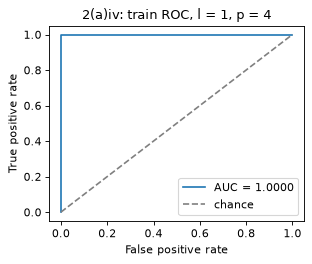

In [29]:
def confusion_table(y_true, y_pred):
    """Confusion matrix with labelled rows (actual class) and columns (predicted class)."""
    matrix = confusion_matrix(y_true, y_pred, labels=[1, 0])
    return pd.DataFrame(matrix, index=["actual bending", "actual other"],
                        columns=["predicted bending", "predicted other"])


def plot_roc(y_true, probability, title):
    """ROC curve with the AUC in the legend."""
    fpr, tpr, _ = roc_curve(y_true, probability)
    with plt.rc_context({"figure.dpi": FIG_DPI}):
        fig, ax = plt.subplots(figsize=(4, 3.4))
        ax.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, probability):.4f}")
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
        ax.set_title(title)
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(loc="lower right")
        fig.tight_layout()
        plt.show()


train_probability = final_model.predict_proba(X_train)[:, 1]
train_prediction = final_model.predict(X_train)
print(confusion_table(y_final, train_prediction).to_string())
print()
print(f"Train accuracy: {accuracy_score(y_final, train_prediction):.4f}")
print(f"Train AUC: {roc_auc_score(y_final, train_probability):.4f}")
plot_roc(y_final, train_probability, f"2(a)iv: train ROC, l = {best_l}, p = {best_p}")

The table gives the coefficients beta_i of the final model, one for each standardized feature, so their sizes can be compared with each other. The p-values come from a statsmodels Logit model (Reference 25) with a constant and the same standardized features.

In [30]:
logistic_fit = final_model[-1].estimator_
coefficients = pd.DataFrame({"feature": ["intercept"] + selected,
                             "beta": np.r_[logistic_fit.intercept_, logistic_fit.coef_[0]]})
print(coefficients.round(4).to_string(index=False))
print("Iterations used by the solver:", logistic_fit.n_iter_[0], "of at most", MAX_ITER)

    feature     beta
  intercept -19.1956
mean_3_seg1 -14.0378
 max_4_seg1   4.0174
 max_5_seg1  17.1872
mean_5_seg1  16.5695
Iterations used by the solver: 15 of at most 100


In [31]:
Z_train = pd.DataFrame(final_model[0].transform(X_train)[:, final_model[-1].support_],
                       columns=selected)
design = sm.add_constant(Z_train)
beta = np.r_[logistic_fit.intercept_, logistic_fit.coef_[0]]
# Start at the scikit-learn coefficients and take no step, so statsmodels only evaluates the standard errors there.
logit = sm.Logit(y_final, design).fit(start_params=beta, method="newton", maxiter=0, disp=0,
                                      warn_convergence=False)
p_values = pd.DataFrame({"feature": ["intercept"] + selected, "beta": logit.params.to_numpy(),
                         "std error": logit.bse.to_numpy(), "z": logit.tvalues.to_numpy(),
                         "p-value": logit.pvalues.to_numpy()})
print(p_values.round(4).to_string(index=False))
print("Largest difference from the scikit-learn coefficients:", np.max(np.abs(logit.params.to_numpy() - beta)))

    feature     beta  std error       z  p-value
  intercept -19.1956    45.7191 -0.4199   0.6746
mean_3_seg1 -14.0378    32.4654 -0.4324   0.6655
 max_4_seg1   4.0174    31.5649  0.1273   0.8987
 max_5_seg1  17.1872    68.4895  0.2509   0.8019
mean_5_seg1  16.5695    92.5833  0.1790   0.8580
Largest difference from the scikit-learn coefficients: 0.0


Every p-value is large, between about 0.67 and 0.90, so none of the four coefficients looks significant on its own. The p-values are computed at the coefficients that scikit-learn found, because the four features separate the train instances perfectly and a statsmodels refit from scratch does not converge. At those coefficients the standard errors are very large, from about 32 to 93, while the intercept and the coefficients are all below 20 in size.

#### v. Test Classifier

The test instances are cut with the same l = 1. The scaler, the selected features and the logistic regression all come from the fit on the train instances, and nothing is refit on the test data.

In [32]:
test_final = segment_features(best_l, split="test")
X_test = test_final[model_columns(best_l)]
y_test = is_bending(test_final)

test_prediction = final_model.predict(X_test)
print(confusion_table(y_test, test_prediction).to_string())
print()
print(f"Test accuracy: {accuracy_score(y_test, test_prediction):.4f} on {len(y_test)} test instances")
print(f"CV accuracy of the chosen pair: {best['cv_accuracy']:.4f}")

                predicted bending  predicted other
actual bending                  3                1
actual other                    1               14

Test accuracy: 0.8947 on 19 test instances
CV accuracy of the chosen pair: 0.9714


The test accuracy is 0.8947, lower than the CV accuracy of 0.9714. The model misclassifies 2 of the 19 test instances, one bending and one other. With only 19 test instances, one misclassified instance moves the test accuracy by about 5 percentage points. So the gap of about 8 points is less than two instances, and it is weak evidence that the model is worse than the CV accuracy suggested.

#### vi. Separation

Yes, the two classes are well separated in the train data, enough to make the logistic regression coefficients unstable. The final model classifies all 69 train instances correctly, and its intercept is -19.20 with coefficients as large as 17.19 on standardized features. The standard errors of the coefficients are also very large, which is another sign of the separation. The scikit-learn fit stops after 15 iterations, before the limit of 100 from footnote 5, so the printed coefficients only show where the fit stopped and are not stable estimates.

#### vii. Imbalance

The classes are imbalanced, since only 9 of the 69 train instances, or 13%, are bending. Case-control sampling keeps all 9 bending instances and draws 9 of the 60 other instances at random without replacement, with a fixed seed. The model uses the same l = 1 and the same four selected features as 2(a)iv. Afterwards the intercept is moved from the bending share of the sample, pi_s = 9/18, to the bending share of the train data, pi = 9/69, as in ISLR section 4.3 (Reference 15).

In [33]:
print("Train instances: bending", y_final.sum(), " other", len(y_final) - y_final.sum())

rng = np.random.default_rng(0)
bending_rows = np.flatnonzero(y_final == 1)
other_rows = np.sort(rng.choice(np.flatnonzero(y_final == 0), size=len(bending_rows), replace=False))
sample_rows = np.concatenate([bending_rows, other_rows])
X_sample, y_sample = X_train.iloc[sample_rows][selected], y_final[sample_rows]
print("Case-control sample: bending", y_sample.sum(), " other", len(y_sample) - y_sample.sum())

case_control = make_pipeline(StandardScaler(), logistic()).fit(X_sample, y_sample)

Train instances: bending 9  other 60
Case-control sample: bending 9  other 9


In [34]:
def adjusted_intercept(beta0, pi, pi_sample):
    """Move the intercept from the bending share of the sample to that of the train data (ISLR 4.3)."""
    return beta0 + np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))


pi, pi_sample = y_final.mean(), y_sample.mean()
fitted_intercept = case_control[-1].intercept_[0]
case_control[-1].intercept_ = np.array([adjusted_intercept(fitted_intercept, pi, pi_sample)])
print(f"pi = {y_final.sum()}/{len(y_final)} = {pi:.4f}, pi_s = {y_sample.sum()}/{len(y_sample)} = {pi_sample:.4f}")
print(f"Fitted intercept: {fitted_intercept:.4f}")
print(f"Adjusted intercept: {case_control[-1].intercept_[0]:.4f}")

pi = 9/69 = 0.1304, pi_s = 9/18 = 0.5000
Fitted intercept: 3.1312
Adjusted intercept: 1.2340


All 69 train instances
                predicted bending  predicted other
actual bending                  9                0
actual other                    1               59
Train accuracy: 0.9855
Train AUC: 1.0000

Test instances
                predicted bending  predicted other
actual bending                  3                1
actual other                    1               14
Test accuracy: 0.8947


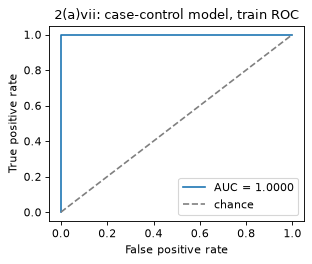

In [35]:
cc_probability = case_control.predict_proba(X_train[selected])[:, 1]
cc_prediction = case_control.predict(X_train[selected])
print("All 69 train instances")
print(confusion_table(y_final, cc_prediction).to_string())
print(f"Train accuracy: {accuracy_score(y_final, cc_prediction):.4f}")
print(f"Train AUC: {roc_auc_score(y_final, cc_probability):.4f}")
print()
cc_test_prediction = case_control.predict(X_test[selected])
print("Test instances")
print(confusion_table(y_test, cc_test_prediction).to_string())
print(f"Test accuracy: {accuracy_score(y_test, cc_test_prediction):.4f}")
plot_roc(y_final, cc_probability, "2(a)vii: case-control model, train ROC")

Case-control sampling does not improve the model here, because the model of 2(a)iv already classifies every bending train instance correctly. The adjusted case-control model ranks the train instances as well as the model of 2(a)iv, with a train AUC of 1.0000. However, it labels one other instance as bending, so its train accuracy is 0.9855 instead of 1.0000. On the test data both models give the same confusion matrix and the same test accuracy of 0.8947.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

2(b)i repeats 2(a)iii with an L1 penalty in place of RFE. The L1 penalty pushes the coefficients of unhelpful features to exactly zero, so the model selects features while it is fit. The features are the same 18 * l features as in 2(a)iii, and they are standardized inside each round, because footnote 8 suggests standardized features and the penalty treats all coefficients alike. The model uses the liblinear solver that footnote 9 recommends (Reference 16). The budget C takes 25 values from 0.01 to 10000 on a log scale, and a smaller C means a stronger penalty. The same five folds as 2(a)iii are used, and the pair (l, C) with the highest CV accuracy is chosen. Ties go to the smallest l and then the smallest C, which gives the strongest penalty and so the simplest model.

In [36]:
C_VALUES = np.logspace(-2, 4, 25)
train_X = {l: train_tables[l][model_columns(l)].to_numpy() for l in L_VALUES}


def l1_logistic(C):
    """Scaler followed by an L1-penalized logistic regression with budget C (liblinear solver)."""
    # l1_ratio=1 is the L1 penalty; scikit-learn 1.9 asks for it this way instead of penalty="l1"
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=1, solver="liblinear",
                                                              max_iter=1000, random_state=0))


def fold_accuracy(model, X, y, fit_rows, held_rows):
    """Fit a fresh copy of the model on the training part of a fold and score the held-out fold."""
    model = clone(model).fit(X[fit_rows], y[fit_rows])
    return accuracy_score(y[held_rows], model.predict(X[held_rows]))


def grid_search(make_model, y, folds, C_values=(None,), n_jobs=-1):
    """CV accuracy of every setting (l, C) on the train instances, with one column per held-out fold."""
    settings = [(l, C) for l in L_VALUES for C in C_values]
    accuracy = Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(fold_accuracy)(make_model(C), train_X[l], y, fit_rows, held_rows)
        for l, C in settings for fit_rows, held_rows in folds)
    accuracy = np.array(accuracy).reshape(len(settings), len(folds))
    grid = pd.DataFrame(settings, columns=["l", "C"])
    grid["cv_accuracy"] = accuracy.mean(axis=1)
    for k in range(len(folds)):
        grid[f"fold_{k + 1}"] = accuracy[:, k]
    return grid


def best_setting(grid, keys):
    """Row with the highest CV accuracy, ties going to the smallest value of each key in turn."""
    score = grid["cv_accuracy"].round(10)  # rounding removes floating-point noise before comparing
    return grid[score == score.max()].sort_values(keys).iloc[0]


def show_best_per_l(grid, keys=("C",)):
    """Print the best setting and its CV accuracy for every l."""
    best = pd.DataFrame([best_setting(grid[grid["l"] == l], list(keys)) for l in L_VALUES])
    columns = ["l"] + list(keys) + ["cv_accuracy"]
    print(best[columns].to_string(index=False, formatters={"l": lambda v: str(int(v)), "C": "{:.4g}".format,
                                                           "cv_accuracy": "{:.4f}".format}))

In [37]:
# liblinear uses one shared random number generator, so its fits run one at a time to stay reproducible
grid_l1 = grid_search(l1_logistic, y_train, folds, C_VALUES, n_jobs=1)
show_best_per_l(grid_l1)

best_l1 = best_setting(grid_l1, ["l", "C"])
l1_l, l1_C = int(best_l1["l"]), float(best_l1["C"])
print()
print(f"Chosen pair: l = {l1_l}, C = {l1_C:.4g}, CV accuracy = {best_l1['cv_accuracy']:.4f}")

 l      C cv_accuracy
 1  1.778      0.9714
 2 0.3162      0.9571
 3 0.3162      0.9714
 4 0.5623      0.9571
 5  1.778      0.9418
 6 0.1778      0.9571
 7      1      0.9571
 8 0.3162      0.9429
 9 0.1778      0.9275
10     10      0.9560
11      1      0.9703
12 0.5623      0.9857
13 0.5623      0.9714
14 0.3162      0.9714
15 0.3162      0.9571
16 0.5623      0.9714
17  1.778      0.9703
18 0.5623      0.9857
19 0.5623      0.9857
20      1      0.9857

Chosen pair: l = 12, C = 0.5623, CV accuracy = 0.9857


In [38]:
X_train_l1 = train_tables[l1_l][model_columns(l1_l)]
test_table_l1 = segment_features(l1_l, split="test")
X_test_l1, y_test_l1 = test_table_l1[model_columns(l1_l)], is_bending(test_table_l1)

l1_model = l1_logistic(l1_C).fit(X_train_l1, y_train)
l1_coef = l1_model[-1].coef_[0]
nonzero = list(X_train_l1.columns[l1_coef != 0])
print(f"Non-zero coefficients: {len(nonzero)} of {len(l1_coef)}")
print(", ".join(nonzero))

l1_train_probability = l1_model.predict_proba(X_train_l1)[:, 1]
l1_test_probability = l1_model.predict_proba(X_test_l1)[:, 1]
print()
print("Train instances")
print(confusion_table(y_train, l1_model.predict(X_train_l1)).to_string())
print(f"Train accuracy: {accuracy_score(y_train, l1_model.predict(X_train_l1)):.4f}")
print(f"Train AUC: {roc_auc_score(y_train, l1_train_probability):.4f}")
print()
print("Test instances")
print(confusion_table(y_test_l1, l1_model.predict(X_test_l1)).to_string())
print(f"Test accuracy: {accuracy_score(y_test_l1, l1_model.predict(X_test_l1)):.4f}")
print(f"Test AUC: {roc_auc_score(y_test_l1, l1_test_probability):.4f}")

Non-zero coefficients: 5 of 216
max_1_seg7, std_3_seg3, mean_5_seg2, mean_5_seg11, max_6_seg11

Train instances
                predicted bending  predicted other
actual bending                  9                0
actual other                    0               60
Train accuracy: 1.0000
Train AUC: 1.0000

Test instances
                predicted bending  predicted other
actual bending                  3                1
actual other                    0               15
Test accuracy: 0.9474
Test AUC: 0.9833


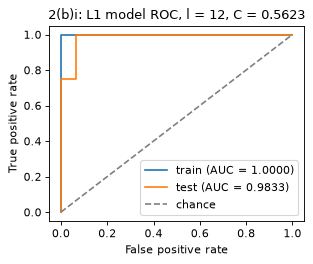

In [39]:
with plt.rc_context({"figure.dpi": FIG_DPI}):
    fig, ax = plt.subplots(figsize=(4, 3.4))
    for name, y_true, probability in (("train", y_train, l1_train_probability),
                                      ("test", y_test_l1, l1_test_probability)):
        fpr, tpr, _ = roc_curve(y_true, probability)
        ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_true, probability):.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
    ax.set_title(f"2(b)i: L1 model ROC, l = {l1_l}, C = {l1_C:.4g}")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

The highest CV accuracy is 0.9857, reached at l = 12, 18, 19 and 20, and the tie rule picks l = 12 with C = 0.5623. The final L1 model keeps only 5 of its 216 coefficients non-zero, so the penalty does the feature selection. The model classifies every train instance correctly and gets 18 of the 19 test instances right, for a test accuracy of 0.9474.

#### ii. Comparison

The L1 model performs slightly better than the model of 2(a), which selects features with RFE instead of p-values, but the difference is not clear. Its CV accuracy is 0.9857 against 0.9714, and its test accuracy is 0.9474 against 0.8947, which is one more correct test instance. One test instance is worth about 5 percentage points, so the test difference alone is not a clear win. The L1 model keeps 5 features at l = 12, while the RFE model keeps 4 features at l = 1. The L1 model is easier to implement, because the penalty selects the features during a single fit, while RFE needs a separate loop that refits the model once for every removed feature.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

2(c) has K = 7 classes, one for each activity, with bending1 and bending2 kept apart. With K classes the confusion matrix becomes a K by K table, with the actual classes in the rows and the predicted classes in the columns, so the diagonal counts the correct predictions. A ROC curve needs two classes, so one curve is drawn for each class against all the other classes together, which is called one-versus-rest. Each curve uses the predicted probability of its class, and the macro-average AUC is the plain mean of the K per-class AUC values. The matrices and curves come from confusion_matrix, roc_curve and roc_auc_score of scikit-learn (References 20, 21 and 22).

2(c)i fits an L1-penalized multinomial logistic regression with the saga solver (Reference 16), called the L1 multinomial regression below. The values of l and C are chosen in the same way as in 2(b)i, with the same features, the same 25 values of C and the scaler fit inside each round. The folds are stratified on the seven classes. The class bending2 has only 4 train instances for 5 folds, so one held-out fold has no bending2 instance. The table counts the instances of each class in each held-out fold, and the same seven-class folds are used for every model in 2(c).

In [40]:
y_multi = train_tables[1]["activity"].to_numpy()
# bending2 has 4 train instances for 5 folds, so this StratifiedKFold warning is expected
warnings.filterwarnings("ignore", message="The least populated class", category=UserWarning)
folds7 = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
              .split(np.zeros(len(y_multi)), y_multi))
fold_classes = pd.DataFrame({f"fold {k + 1}": pd.Series(y_multi[held]).value_counts()
                             for k, (_, held) in enumerate(folds7)})
print(fold_classes.reindex(ACTIVITIES).fillna(0).astype(int).to_string())

          fold 1  fold 2  fold 3  fold 4  fold 5
bending1       1       1       1       1       1
bending2       1       1       1       1       0
cycling        3       2       2       2       3
lying          2       3       3       2       2
sitting        2       2       2       3       3
standing       3       3       2       2       2
walking        2       2       3       3       2


In [41]:
def l1_multinomial(C):
    """Scaler followed by an L1-penalized multinomial logistic regression with budget C (saga solver)."""
    # saga can stop at max_iter for some C; that ConvergenceWarning is already silenced in 2(a)iii
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=1, solver="saga",
                                                              max_iter=5000, random_state=0))


grid_multi = grid_search(l1_multinomial, y_multi, folds7, C_VALUES)
show_best_per_l(grid_multi)

best_multi = best_setting(grid_multi, ["l", "C"])
multi_l, multi_C = int(best_multi["l"]), float(best_multi["C"])
print()
print(f"Chosen pair: l = {multi_l}, C = {multi_C:.4g}, CV accuracy = {best_multi['cv_accuracy']:.4f}")

 l      C cv_accuracy
 1  1.778      0.9121
 2 0.5623      0.8681
 3     10      0.8538
 4     10      0.8407
 5  3.162      0.8681
 6  316.2      0.8670
 7  316.2      0.8242
 8  31.62      0.8242
 9  316.2      0.8242
10  31.62      0.8231
11  3.162      0.8099
12  1.778      0.7945
13  177.8      0.7802
14  177.8      0.8088
15     10      0.7945
16     10      0.8231
17  3.162      0.8670
18  177.8      0.8538
19  316.2      0.8088
20  56.23      0.8099

Chosen pair: l = 1, C = 1.778, CV accuracy = 0.9121


In [42]:
def confusion_table_multi(y_true, y_pred):
    """Seven-class confusion matrix with actual classes in rows and predicted classes in columns."""
    matrix = confusion_matrix(y_true, y_pred, labels=ACTIVITIES)
    return pd.DataFrame(matrix, index=pd.Index(ACTIVITIES, name="actual"),
                        columns=pd.Index(ACTIVITIES, name="predicted"))


def multiclass_roc(ax, y_true, probability, classes, title):
    """One-versus-rest ROC curve for every class, with the per-class AUC in the legend."""
    aucs = {}
    for k, label in enumerate(classes):
        aucs[label] = roc_auc_score(y_true == label, probability[:, k])
        fpr, tpr, _ = roc_curve(y_true == label, probability[:, k])
        ax.plot(fpr, tpr, label=f"{label} (AUC = {aucs[label]:.2f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set_title(title)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", fontsize=7)
    return aucs


def test_set(l):
    """Test features (mean, std and max of l segments) and seven-class labels."""
    table = segment_features(l, split="test")
    return table[model_columns(l)], table["activity"].to_numpy()


X_test_multi, y_test_multi = test_set(multi_l)
multi_model = l1_multinomial(multi_C).fit(train_tables[multi_l][model_columns(multi_l)], y_multi)
multi_prediction = multi_model.predict(X_test_multi)
multi_error = 1 - accuracy_score(y_test_multi, multi_prediction)
print(f"Test error: {multi_error:.4f} on {len(y_test_multi)} test instances")
print(confusion_table_multi(y_test_multi, multi_prediction).to_string())

Test error: 0.1053 on 19 test instances
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
actual                                                                   
bending1          2         0        0      0        0         0        0
bending2          0         2        0      0        0         0        0
cycling           0         0        3      0        0         0        0
lying             0         0        0      3        0         0        0
sitting           0         0        0      0        2         1        0
standing          0         0        0      1        0         2        0
walking           0         0        0      0        0         0        3


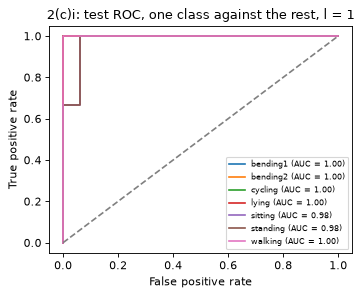

Per-class test AUC: bending1 1.0000, bending2 1.0000, cycling 1.0000, lying 1.0000, sitting 0.9792, standing 0.9792, walking 1.0000
Macro-average test AUC: 0.9940


In [43]:
multi_probability = multi_model.predict_proba(X_test_multi)
with plt.rc_context({"figure.dpi": FIG_DPI}):
    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    multi_auc = multiclass_roc(ax, y_test_multi, multi_probability, multi_model.classes_,
                               f"2(c)i: test ROC, one class against the rest, l = {multi_l}")
    fig.tight_layout()
    plt.show()
print("Per-class test AUC:", ", ".join(f"{label} {auc:.4f}" for label, auc in multi_auc.items()))
print(f"Macro-average test AUC: {np.mean(list(multi_auc.values())):.4f}")

The chosen pair is l = 1 and C = 1.778, with a CV accuracy of 0.9121. The test error, which is one minus the test accuracy, is 0.1053, so 2 of the 19 test instances are misclassified. One sitting instance is predicted as standing and one standing instance as lying. The macro-average test AUC is 0.9940, and only sitting and standing have a per-class AUC below 1.

#### ii. Naive Bayes

2(c)ii repeats 2(c)i with a Gaussian naive Bayes model (Gaussian NB, Reference 23) and a multinomial naive Bayes model (multinomial NB, Reference 24). Naive Bayes has no budget C, so only l is cross-validated, on the same seven-class folds, with ties going to the smallest l. Both models use the features without standardizing, because standardizing would create negative values that multinomial NB cannot use. Every mean, standard deviation and maximum of this data is non-negative, and the code checks every value before fitting.

In [44]:
def assert_non_negative(X):
    """MultinomialNB only accepts non-negative features."""
    assert (np.asarray(X) >= 0).all(), "found a negative feature value"


for l in L_VALUES:
    assert_non_negative(train_X[l])
    assert_non_negative(test_set(l)[0])

grid_gnb = grid_search(lambda C: GaussianNB(), y_multi, folds7).drop(columns="C")
grid_mnb = grid_search(lambda C: MultinomialNB(), y_multi, folds7).drop(columns="C")
nb_cv = pd.DataFrame({"l": list(L_VALUES), "Gaussian NB": grid_gnb["cv_accuracy"],
                      "multinomial NB": grid_mnb["cv_accuracy"]})
print(nb_cv.round(4).to_string(index=False))

 l  Gaussian NB  multinomial NB
 1       0.8538          0.8253
 2       0.8264          0.8407
 3       0.8099          0.8407
 4       0.8396          0.8407
 5       0.8538          0.8253
 6       0.8253          0.8110
 7       0.8396          0.8418
 8       0.7967          0.8418
 9       0.7681          0.8275
10       0.7670          0.8110
11       0.7956          0.8714
12       0.7813          0.7967
13       0.6956          0.8560
14       0.7538          0.8560
15       0.7527          0.8132
16       0.7527          0.8418
17       0.7385          0.8121
18       0.7385          0.7989
19       0.7813          0.8121
20       0.7099          0.7978


In [45]:
nb_results = {}
for name, grid, make in (("Gaussian NB", grid_gnb, GaussianNB), ("multinomial NB", grid_mnb, MultinomialNB)):
    best = best_setting(grid, ["l"])
    l = int(best["l"])
    X_test_nb, y_test_nb = test_set(l)
    model = make().fit(train_X[l], y_multi)
    prediction = model.predict(X_test_nb.to_numpy())
    nb_results[name] = {"l": l, "cv": best["cv_accuracy"], "model": model, "X_test": X_test_nb.to_numpy(),
                        "error": 1 - accuracy_score(y_test_nb, prediction)}
    print(f"{name}: chosen l = {l}, CV accuracy = {best['cv_accuracy']:.4f}, "
          f"test error = {nb_results[name]['error']:.4f}")
    print(confusion_table_multi(y_test_nb, prediction).to_string())
    print()

Gaussian NB: chosen l = 1, CV accuracy = 0.8538, test error = 0.1053
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
actual                                                                   
bending1          2         0        0      0        0         0        0
bending2          0         1        0      0        1         0        0
cycling           0         0        3      0        0         0        0
lying             0         0        0      3        0         0        0
sitting           0         0        0      0        3         0        0
standing          0         0        0      0        1         2        0
walking           0         0        0      0        0         0        3



multinomial NB: chosen l = 11, CV accuracy = 0.8714, test error = 0.0526
predicted  bending1  bending2  cycling  lying  sitting  standing  walking
actual                                                                   
bending1          2         0        0      0        0         0        0
bending2          0         2        0      0        0         0        0
cycling           0         0        3      0        0         0        0
lying             0         0        0      3        0         0        0
sitting           0         0        0      0        2         1        0
standing          0         0        0      0        0         3        0
walking           0         0        0      0        0         0        3



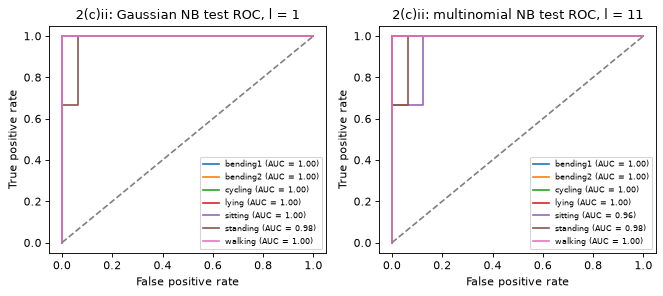

Gaussian NB macro-average test AUC: 0.9970
multinomial NB macro-average test AUC: 0.9911


In [46]:
with plt.rc_context({"figure.dpi": FIG_DPI}):
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8))
    nb_auc = {}
    for ax, (name, result) in zip(axes, nb_results.items()):
        nb_auc[name] = multiclass_roc(ax, y_test_multi, result["model"].predict_proba(result["X_test"]),
                                      result["model"].classes_, f"2(c)ii: {name} test ROC, l = {result['l']}")
    fig.tight_layout()
    plt.show()
for name, aucs in nb_auc.items():
    print(f"{name} macro-average test AUC: {np.mean(list(aucs.values())):.4f}")

Multinomial NB does slightly better than Gaussian NB, but the margin is small. Multinomial NB chooses l = 11, with a CV accuracy of 0.8714 and a test error of 0.0526, which is 1 misclassified test instance. Gaussian NB chooses l = 1, with a CV accuracy of 0.8538 and a test error of 0.1053, which is 2 misclassified test instances. Both naive Bayes models have a lower CV accuracy than the L1 multinomial regression.

#### ii. Comparison

In [47]:
summary = pd.DataFrame({
    "model": ["L1 multinomial regression", "Gaussian NB", "multinomial NB"],
    "chosen l": [multi_l, nb_results["Gaussian NB"]["l"], nb_results["multinomial NB"]["l"]],
    "CV accuracy": [best_multi["cv_accuracy"], nb_results["Gaussian NB"]["cv"], nb_results["multinomial NB"]["cv"]],
    "test error": [multi_error, nb_results["Gaussian NB"]["error"], nb_results["multinomial NB"]["error"]]})
print(summary.round(4).to_string(index=False))

                    model  chosen l  CV accuracy  test error
L1 multinomial regression         1       0.9121      0.1053
              Gaussian NB         1       0.8538      0.1053
           multinomial NB        11       0.8714      0.0526


The L1 multinomial regression is the best of the three methods for multi-class classification here. It has the highest CV accuracy, 0.9121, against 0.8538 for Gaussian NB and 0.8714 for multinomial NB. Multinomial NB has the lowest test error, 0.0526 against 0.1053 for the other two models, but the gap is one test instance out of 19, or about 5 percentage points. The CV accuracy comes from all 69 train instances over five held-out folds, so it gives the steadier comparison, and it favors the L1 multinomial regression.

## 3. ISLR 4.8.3

The Bayes classifier is not linear when the class variances differ, and it is quadratic in x. The steps follow Section 4.4.1 of ISLR (Reference 15) without assuming equal variances. Here pi_k is the prior probability of class k, and in class k the feature X is normal with mean mu_k and variance sigma_k^2. The letter x stands for an observed value of X.

1. The Bayes classifier assigns x to the class k with the largest posterior probability `p_k(x) = pi_k f_k(x) / (pi_1 f_1(x) + ... + pi_K f_K(x))`, where f_k is the normal density of class k and K is the number of classes. The denominator is the same for every class, so the classifier picks the class with the largest `pi_k f_k(x)`.
2. The normal density is `f_k(x) = exp(-(x - mu_k)^2 / (2 sigma_k^2)) / (sqrt(2 pi) sigma_k)`, where the pi inside `sqrt(2 pi)` is the number 3.14159, not a prior probability.
3. The logarithm is increasing, so the class with the largest `log(pi_k f_k(x))` is chosen. Dropping `log(sqrt(2 pi))`, which is the same for every class, leaves `log(pi_k) - log(sigma_k) - (x - mu_k)^2 / (2 sigma_k^2)`.
4. Expanding the square gives the discriminant `delta_k(x) = - x^2 / (2 sigma_k^2) + x mu_k / sigma_k^2 - mu_k^2 / (2 sigma_k^2) - log(sigma_k) + log(pi_k)`.
5. If all classes share one variance, the x^2 term is the same for every class and cancels when two classes are compared. What is left is linear in x, which is the rule of linear discriminant analysis (LDA) in Section 4.4.1.
6. If the variances differ, `delta_j(x) - delta_k(x) = a x^2 + b x + c` for some numbers b and c, with `a = 1 / (2 sigma_k^2) - 1 / (2 sigma_j^2)`, which is not zero when sigma_j and sigma_k differ. The boundary between classes j and k is then the solution of a quadratic equation in x, which can have two roots, so one class can win on an interval between two cut points.

So the Bayes classifier compares functions that are quadratic in x, and it is not linear. It is a quadratic classifier, which is the rule of quadratic discriminant analysis (QDA) for one feature.

## 4. ISLR 4.8.7

The probability is about 0.752. By Bayes' theorem (ISLR, Reference 15), `P(Yes | X = 4) = 0.8 f_Yes(4) / (0.8 f_Yes(4) + 0.2 f_No(4))`, where f_Yes and f_No are normal densities with means 10 and 0 and the same variance 36. The factor `1 / sqrt(2 pi 36)` is the same in both densities and cancels, which leaves `0.8 exp(-(4 - 10)^2 / 72) / (0.8 exp(-(4 - 10)^2 / 72) + 0.2 exp(-(4 - 0)^2 / 72))`. The exponents are -36/72 = -1/2 and -16/72 = -2/9, so the probability is `0.8 exp(-1/2) / (0.8 exp(-1/2) + 0.2 exp(-2/9))`, which the code below evaluates.

In [48]:
dividend = 0.8 * np.exp(-(4 - 10) ** 2 / (2 * 36))
no_dividend = 0.2 * np.exp(-(4 - 0) ** 2 / (2 * 36))
p_dividend = dividend / (dividend + no_dividend)
print(f"P(Yes | X = 4) = {p_dividend:.5f}")

P(Yes | X = 4) = 0.75185


## 5.1. Extra Practice ISLR 4.8.4

The assignment lists ISLR 4.8.4 as extra practice, and its answers are not submitted.

## 5.2. Extra Practice ISLR 4.8.9

The assignment lists ISLR 4.8.9 as extra practice, and its answers are not submitted.

## References

1. AReM data set, UCI Machine Learning Repository. https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. NumPy documentation, numpy.min. https://numpy.org/doc/stable/reference/generated/numpy.min.html
3. NumPy documentation, numpy.max. https://numpy.org/doc/stable/reference/generated/numpy.max.html
4. NumPy documentation, numpy.mean. https://numpy.org/doc/stable/reference/generated/numpy.mean.html
5. NumPy documentation, numpy.median. https://numpy.org/doc/stable/reference/generated/numpy.median.html
6. NumPy documentation, numpy.std. https://numpy.org/doc/stable/reference/generated/numpy.std.html
7. NumPy documentation, numpy.percentile. https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
8. NumPy documentation, random Generator and default_rng. https://numpy.org/doc/stable/reference/random/generator.html
9. NumPy documentation, numpy.random.Generator.integers. https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html
10. pandas documentation, pandas.DataFrame.corr. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
11. Matplotlib documentation, matplotlib.axes.Axes.bar. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar.html
12. F. Demrozi, G. Pravadelli, A. Bihorac and P. Rashidi, Human Activity Recognition using Inertial, Physiological and Environmental Sensors: A Comprehensive Survey. arXiv:2004.08821. https://arxiv.org/abs/2004.08821
13. NumPy documentation, numpy.array_split. https://numpy.org/doc/stable/reference/generated/numpy.array_split.html
14. seaborn documentation, seaborn.pairplot. https://seaborn.pydata.org/generated/seaborn.pairplot.html
15. G. James, D. Witten, T. Hastie and R. Tibshirani, An Introduction to Statistical Learning, second edition. https://www.statlearning.com/
16. scikit-learn documentation, sklearn.linear_model.LogisticRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
17. scikit-learn documentation, sklearn.feature_selection.RFE. https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
18. scikit-learn documentation, sklearn.model_selection.StratifiedKFold. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
19. scikit-learn documentation, sklearn.preprocessing.StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
20. scikit-learn documentation, sklearn.metrics.roc_curve. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html
21. scikit-learn documentation, sklearn.metrics.roc_auc_score. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
22. scikit-learn documentation, sklearn.metrics.confusion_matrix. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
23. scikit-learn documentation, sklearn.naive_bayes.GaussianNB. https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
24. scikit-learn documentation, sklearn.naive_bayes.MultinomialNB. https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
25. statsmodels documentation, statsmodels.discrete.discrete_model.Logit. https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html